# 🌉 Lesson 15 · Keras & TensorFlow Bridge

*“Once you've learned to drive one car, learning another is a matter of finding the indicator.”*

| ⏱ Time | 🎚 Level | 🗓 Suggested day | 📚 You should know |
|:--|:--|:--|:--|
| ~100 min | 🟡 Intermediate | Day 13 | Lessons 05–09 (PyTorch training loop, CNNs) |

## 🎯 Learning objectives
By the end of this lesson you will be able to:

- Place **PyTorch, TensorFlow, Keras and JAX** on the map and know when each is the better choice
- Translate between PyTorch and Keras with a **Rosetta-stone table**: models, losses, optimisers, training loops
- Build, compile, train and evaluate **Keras `Sequential` and Functional models**, and verify parameter counts match PyTorch
- Use Keras **callbacks** (early stopping, LR reduction, checkpoints) and recognise what `dl.fit` was doing
- Write a **TensorFlow custom training loop** with `tf.GradientTape` and a **`tf.data`** pipeline
- Handle the **channels-last** convention
- **Export** a model for deployment: Keras `.keras` files and **TensorFlow Lite** (including quantisation) for phones

## 🗺 Roadmap
1. The framework landscape
2. Setup
3. Rosetta stone
4. An MLP in both frameworks
5. A CNN in Keras (summary & param counts)
6. Functional API
7. Callbacks
8. An LSTM in Keras
9. TensorFlow specifics: tf.data & GradientTape
10. Deployment: saving, TFLite, quantisation
11. Which framework when?
12. Problems

## ⚙️ Setup
Run this cell first. It loads our libraries and the course helper module (`utils/dlcourse.py`).

In [1]:
import sys; sys.path.append("..")          # so we can import the course helper library
import numpy as np
import matplotlib.pyplot as plt
from utils import dlcourse as dl
import os, time, warnings
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"                  # keep TensorFlow's chatty logs quiet
warnings.filterwarnings("ignore")
try:
    import tensorflow as tf
    BACKEND = "tensorflow"
except ImportError:                                        # no TensorFlow? Keras 3 can run on top of PyTorch!
    tf = None
    os.environ["KERAS_BACKEND"] = "torch"
    BACKEND = "torch"
import keras
import torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
cpu = torch.device("cpu")
print("Keras", keras.__version__, "| Keras backend:", keras.backend.backend(), "| TensorFlow available:", tf is not None)
dl.set_seed(42)                          # reproducible randomness
%matplotlib inline

I0000 00:00:1794724242.897540     769 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1794724259.411161     769 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Keras 3.15.1 | Keras backend: tensorflow | TensorFlow available: True


---
## 🗺 1. The framework landscape

| Name | What it is | Strengths | Typical home |
|:--|:--|:--|:--|
| **PyTorch** | Define-by-run tensor library with autograd (Meta → Linux Foundation) | Pythonic, easy debugging, huge research ecosystem | Research, most new papers, LLM training |
| **TensorFlow** | Graph/tensor framework (Google) | Mature **deployment** tooling: TF Serving, **TensorFlow Lite** (phones/edge), TF.js (browsers) | Production pipelines, mobile/edge |
| **Keras** | High-level API: layers, `compile`, `fit` | Fastest way to a working model; readable | Beginners, prototyping, applied ML |
| **JAX** | NumPy + autodiff + compiler (Google) | Speed, functional style, TPUs | Cutting-edge research |

**Keras 3 is multi-backend:** the *same Keras code* can run on **TensorFlow, PyTorch or JAX**. (If TensorFlow isn't installed, this notebook transparently runs Keras on PyTorch; try it!)

> 🌍 **Why this matters in agriculture.** Farmers' phones are often low-end, offline, and short on memory. Getting a model onto such a device means **converting and shrinking** it. TensorFlow Lite (and ONNX / PyTorch's mobile tooling) exist for exactly that, and the skills in this lesson (Keras models, SavedModel export, quantisation) are the usual route. Many real crop-diagnosis apps ship TFLite models.

**Good news:** every idea you learned (tensors, layers, loss, backprop, optimisers, CNNs, LSTMs, regularisation) is framework-independent. Only the *spelling* changes.

---
## 🪨 2. The Rosetta stone

| Concept | PyTorch | Keras |
|:--|:--|:--|
| Dense layer | `nn.Linear(n_in, n_out)` | `layers.Dense(n_out)` *(infers `n_in`)* |
| Activation | `nn.ReLU()` / `F.relu` | `activation="relu"` or `layers.ReLU()` |
| Conv layer | `nn.Conv2d(c_in, c_out, k, padding=...)` | `layers.Conv2D(c_out, k, padding="same"/"valid")` |
| Pooling | `nn.MaxPool2d(2)` | `layers.MaxPooling2D(2)` |
| Flatten | `nn.Flatten()` | `layers.Flatten()` |
| Dropout / BatchNorm | `nn.Dropout(p)` / `nn.BatchNorm2d(c)` | `layers.Dropout(p)` / `layers.BatchNormalization()` |
| Recurrent | `nn.LSTM(n_in, h, batch_first=True)` | `layers.LSTM(h)` *(batch-first by default)* |
| Model container | `nn.Sequential(...)` / `nn.Module` | `keras.Sequential([...])` / `keras.Model` (functional) |
| Loss (multi-class) | `nn.CrossEntropyLoss()` | `SparseCategoricalCrossentropy(from_logits=True)` |
| Optimiser | `torch.optim.Adam(model.parameters(), lr)` | `keras.optimizers.Adam(lr)` |
| The training loop | write it (or `dl.fit`) | **`model.compile(...)` then `model.fit(...)`** |
| Evaluate / predict | loop under `no_grad()` | `model.evaluate(x, y)` / `model.predict(x)` |
| Early stopping etc. | `dl.EarlyStopper`, schedulers | `callbacks=[EarlyStopping(...), ...]` |
| Save weights | `torch.save(model.state_dict(), f)` | `model.save("m.keras")` (architecture + weights) |
| Image layout | **N, C, H, W** (channels first) | **N, H, W, C** (channels last) |
| Autograd | `loss.backward()` | `tf.GradientTape()` (TensorFlow) |
| Data pipeline | `Dataset` / `DataLoader` | `tf.data.Dataset` (or plain NumPy arrays) |

> ⚠️ **Two gotchas when translating:** (1) **channels last** in Keras/TF; (2) Keras infers input sizes (it needs an `Input(shape)` (or builds on first call)) and *its* default weight initialisers differ (Glorot uniform vs PyTorch's Kaiming-uniform variant), so identical architectures give *similar but not identical* results.

---
## 🧪 3. The same MLP in both frameworks

In [2]:
x_tr, y_tr, x_te, y_te = dl.load_mnist(n_train=5000, n_test=2000)
mu, sd = x_tr.mean(), x_tr.std()
Xtr, Xte = ((x_tr - mu) / sd).astype("float32"), ((x_te - mu) / sd).astype("float32")      # (N, 28, 28)

# ----- Keras: compile + fit -----
dl.set_seed(0); keras.utils.set_random_seed(0)
k_mlp = keras.Sequential([
    keras.layers.Input((28, 28)), keras.layers.Flatten(),
    keras.layers.Dense(128, activation="relu"), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(10)])
k_mlp.compile(optimizer=keras.optimizers.Adam(1e-3), loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
t0 = time.time(); hk = k_mlp.fit(Xtr, y_tr, validation_data=(Xte, y_te), epochs=6, batch_size=64, verbose=0)
print(f"Keras  : params {k_mlp.count_params():,} | val acc {hk.history['val_accuracy'][-1]:.3f} | {time.time() - t0:.1f}s")

# ----- PyTorch: our own loop via dl.fit -----
dl.set_seed(0)
t_mlp = nn.Sequential(nn.Flatten(), nn.Linear(784, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 10))
tr = DataLoader(TensorDataset(torch.tensor(Xtr), torch.tensor(y_tr)), batch_size=64, shuffle=True)
va = DataLoader(TensorDataset(torch.tensor(Xte), torch.tensor(y_te)), batch_size=1000)
ht = dl.fit(t_mlp, tr, va, nn.CrossEntropyLoss(), torch.optim.Adam(t_mlp.parameters(), 1e-3), epochs=6, device=cpu, verbose=False)
print(f"PyTorch: params {dl.count_params(t_mlp):,} | val acc {ht['val_acc'][-1]:.3f} | {ht['seconds']:.1f}s")

Keras  : params 109,386 | val acc 0.930 | 3.0s


PyTorch: params 109,386 | val acc 0.934 | 1.1s


> 💡 **Big idea**: Same architecture → the **same parameter count** (109,386, just as we counted by hand in Lesson 02) and nearly the same accuracy. `compile` = 'choose loss, optimiser, metrics'; `fit` = *the training loop you wrote in Lesson 05* (including shuffling, batching, validation).

---
## 🔍 4. A CNN in Keras: and `model.summary()`

Here is Lesson 08's mini-LeNet in Keras. Remember the layout: **channels last**: images are `(N, 28, 28, 1)`. Keras' `summary()` prints each layer's output shape and parameter count (a built-in shape tracer!).

In [3]:
k_cnn = keras.Sequential([
    keras.layers.Input((28, 28, 1)),
    keras.layers.Conv2D(8, 5, padding="same", activation="relu"), keras.layers.MaxPooling2D(2),
    keras.layers.Conv2D(16, 5, padding="same", activation="relu"), keras.layers.MaxPooling2D(2),
    keras.layers.Flatten(), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(10)])
k_cnn.summary()
print("PyTorch version of the same CNN had 54,314 parameters (Lesson 08).  Keras:", f"{k_cnn.count_params():,}")

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 8)      │           208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 16)     │         3,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 54,314 (212.16 KB)

 Trainable params: 54,314 (212.16 KB)

 Non-trainable params: 0 (0.00 B)

PyTorch version of the same CNN had 54,314 parameters (Lesson 08).  Keras: 54,314


In [4]:
k_cnn.compile(optimizer=keras.optimizers.Adam(1e-3), loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
t0 = time.time()
h_cnn = k_cnn.fit(Xtr[..., None], y_tr, validation_data=(Xte[..., None], y_te), epochs=5, batch_size=64, verbose=0)       # [..., None] adds the channel axis (last!)
print(f"CNN val acc per epoch: {np.round(h_cnn.history['val_accuracy'], 3)}  ({time.time() - t0:.0f}s)")
loss, acc = k_cnn.evaluate(Xte[..., None], y_te, verbose=0)
probs = keras.ops.softmax(k_cnn.predict(Xte[:3, ..., None], verbose=0))
print(f"evaluate(): loss {loss:.3f}, accuracy {acc:.3f} | predicted classes for 3 images: {np.argmax(probs, 1)} (true: {y_te[:3]})")

CNN val acc per epoch: [0.918 0.95  0.958 0.964 0.965]  (7s)


evaluate(): loss 0.100, accuracy 0.965 | predicted classes for 3 images: [8 6 2] (true: [8 6 2])


---
## 🧬 5. The Functional API

`Sequential` handles straight stacks. For **branches, skip-connections or multiple inputs** (like a ResNet's `x + f(x)`) use the **Functional API**: call layers on tensors and wrap input→output in a `Model`.

In [5]:
inp = keras.Input((20,), name="features")
x = keras.layers.Dense(32, activation="relu")(inp)
y = keras.layers.Dense(32)(x)
x = keras.layers.Activation("relu")(keras.layers.Add()([x, y]))        # a residual (skip) connection, as in ResNet
out = keras.layers.Dense(3, name="logits")(x)
res_model = keras.Model(inp, out, name="tiny_residual_net")
res_model.summary()

Model: "tiny_residual_net"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ features            │ (None, 20)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_5 (Dense)     │ (None, 32)        │        672 │ features[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_6 (Dense)     │ (None, 32)        │      1,056 │ dense_5[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32)        │          0 │ dense_5[0][0],    │
│                     │                   │            │ dense_6[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation          │ (None, 32)        │          0 │ add[0][0]         │
│ (Activation)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ logits (Dense)      │ (None, 3)         │         99 │ activation[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,827 (7.14 KB)

 Trainable params: 1,827 (7.14 KB)

 Non-trainable params: 0 (0.00 B)

---
## 📞 6. Callbacks: the hooks `dl.fit` had built in

| Keras callback | Equivalent in our PyTorch code |
|:--|:--|
| `EarlyStopping(patience, restore_best_weights=True)` | `dl.EarlyStopper` |
| `ReduceLROnPlateau(factor, patience)` | `ReduceLROnPlateau` scheduler |
| `LearningRateScheduler(fn)` | any `lr_scheduler` |
| `ModelCheckpoint(path, save_best_only=True)` | saving `state_dict` at the best epoch |
| `TensorBoard`, `CSVLogger` | logging the `history` dict |

In [6]:
keras.utils.set_random_seed(0)
m = keras.Sequential([keras.layers.Input((28, 28)), keras.layers.Flatten(), keras.layers.Dense(256, activation="relu"), keras.layers.Dense(10)])
m.compile(optimizer=keras.optimizers.Adam(3e-3), loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
cbs = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
       keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=1, verbose=0)]
h = m.fit(Xtr[:1500], y_tr[:1500], validation_data=(Xte, y_te), epochs=40, batch_size=32, callbacks=cbs, verbose=0)
print(f"trained for {len(h.history['loss'])} of 40 epochs (stopped early) | best val_loss {min(h.history['val_loss']):.3f}")
print("learning rate by epoch:", [float(f"{lr:.1e}") for lr in h.history["learning_rate"]] if "learning_rate" in h.history else "n/a")

trained for 9 of 40 epochs (stopped early) | best val_loss 0.289
learning rate by epoch: [0.003, 0.003, 0.003, 0.0015, 0.0015, 0.00075, 0.00075, 0.00038, 0.00019]


---
## 📈 7. An LSTM in Keras

test MSE 0.0164  (noise variance is 0.01; predicting the mean would give ≈ 0.62)


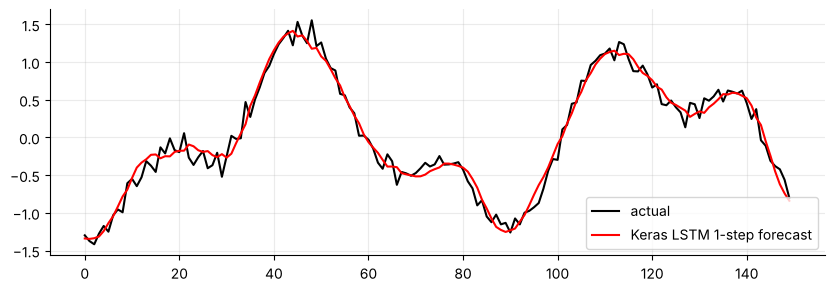

In [7]:
t = np.arange(1400); series = np.sin(t / 12) + 0.5 * np.sin(t / 5) + 0.1 * np.random.default_rng(0).normal(size=len(t))
win = 30
X = np.stack([series[i:i + win] for i in range(len(series) - win)])[..., None].astype("float32")      # (N, 30, 1) : keras LSTM is batch-first
y = series[win:].astype("float32")
n_tr = 1000
keras.utils.set_random_seed(0)
lstm = keras.Sequential([keras.layers.Input((win, 1)), keras.layers.LSTM(32), keras.layers.Dense(1)])
lstm.compile(optimizer=keras.optimizers.Adam(5e-3), loss="mse")
lstm.fit(X[:n_tr], y[:n_tr], epochs=12, batch_size=32, verbose=0, validation_data=(X[n_tr:], y[n_tr:]))
pred = lstm.predict(X[n_tr:], verbose=0)[:, 0]
print(f"test MSE {np.mean((pred - y[n_tr:]) ** 2):.4f}  (noise variance is 0.01; predicting the mean would give ≈ {y[n_tr:].var():.2f})")
plt.figure(figsize=(10, 3.2)); plt.plot(y[n_tr:][:150], "k", label="actual"); plt.plot(pred[:150], "r", label="Keras LSTM 1-step forecast"); plt.legend(); plt.show()

---
## ⚙️ 8. TensorFlow specifics: `tf.data` and `tf.GradientTape`

Underneath Keras, TensorFlow gives you the same primitives PyTorch does. Two to know:

* **`tf.data`**: pipelines: `from_tensor_slices → shuffle → batch → prefetch` (≈ PyTorch's `Dataset`+`DataLoader`).
* **`tf.GradientTape`**: *records* operations so you can ask for gradients (≈ autograd). A custom training step is the five-step loop again:

| The five steps | PyTorch | TensorFlow |
|:--|:--|:--|
| 1. forward | `pred = model(x)` | `with tf.GradientTape() as tape: pred = model(x, training=True)` |
| 2. loss | `loss = loss_fn(pred, y)` | `loss = loss_fn(y, pred)` *(note: truth first!)* |
| 3. zero grads | `optimizer.zero_grad()` | *(not needed; the tape is fresh each time)* |
| 4. backward | `loss.backward()` | `grads = tape.gradient(loss, model.trainable_variables)` |
| 5. step | `optimizer.step()` | `optimizer.apply_gradients(zip(grads, vars))` |

In [8]:
if tf is None:
    print("TensorFlow isn't installed here: run `pip install tensorflow` to try this cell. (Everything above ran on Keras-with-PyTorch.)")
else:
    ds = tf.data.Dataset.from_tensor_slices((Xtr, y_tr)).shuffle(2000, seed=0).batch(64).prefetch(1)
    keras.utils.set_random_seed(0)
    model = keras.Sequential([keras.layers.Input((28, 28)), keras.layers.Flatten(), keras.layers.Dense(64, activation="relu"), keras.layers.Dense(10)])
    opt = keras.optimizers.Adam(1e-3); loss_fn = keras.losses.SparseCategoricalCrossentropy(from_logits=True)

    @tf.function                                           # compile the step into a fast graph
    def train_step(xb, yb):
        with tf.GradientTape() as tape:
            loss = loss_fn(yb, model(xb, training=True))
        grads = tape.gradient(loss, model.trainable_variables)
        opt.apply_gradients(zip(grads, model.trainable_variables))
        return loss

    for epoch in range(1, 4):
        losses = [float(train_step(xb, yb)) for xb, yb in ds]
        acc = np.mean(np.argmax(model(Xte).numpy(), 1) == y_te)
        print(f"epoch {epoch}: mean train loss {np.mean(losses):.3f} | val acc {acc:.3f}")

epoch 1: mean train loss 0.809 | val acc 0.889
epoch 2: mean train loss 0.340 | val acc 0.908


epoch 3: mean train loss 0.254 | val acc 0.922


---
## 📦 9. Deployment: saving, TensorFlow Lite and quantisation

* **Keras `.keras` file** stores architecture + weights + optimiser state in one file → `keras.saving.load_model(path)` brings it back.
* **TensorFlow Lite (`.tflite`)**: a compact format for phones/microcontrollers. **Quantisation** stores weights in 8-bit instead of 32-bit: ~4× smaller, usually faster, typically a tiny accuracy loss.

In [9]:
import tempfile
path = os.path.join(tempfile.gettempdir(), "mnist_cnn.keras")
k_cnn.save(path)
reloaded = keras.saving.load_model(path)
same = np.allclose(k_cnn.predict(Xte[:50, ..., None], verbose=0), reloaded.predict(Xte[:50, ..., None], verbose=0), atol=1e-5)
print(f".keras file: {os.path.getsize(path) / 1024:.0f} KB | reloaded model gives identical predictions: {same}")

.keras file: 673 KB | reloaded model gives identical predictions: True


In [10]:
if tf is None:
    print("TensorFlow isn't installed; TFLite conversion needs it. Install TensorFlow to run this cell.")
else:
    export_dir = tempfile.mkdtemp(); k_cnn.export(export_dir)                      # SavedModel: the format converters understand
    tflite_fp32 = tf.lite.TFLiteConverter.from_saved_model(export_dir).convert()
    conv = tf.lite.TFLiteConverter.from_saved_model(export_dir); conv.optimizations = [tf.lite.Optimize.DEFAULT]
    tflite_q = conv.convert()                                                       # dynamic-range quantisation: weights → 8-bit
    print(f"Keras .keras: {os.path.getsize(path) / 1024:.0f} KB | TFLite float32: {len(tflite_fp32) / 1024:.0f} KB | TFLite quantised: {len(tflite_q) / 1024:.0f} KB")

    def tflite_predict(blob, images):
        it = tf.lite.Interpreter(model_content=blob); it.allocate_tensors()
        i, o = it.get_input_details()[0], it.get_output_details()[0]; out = []
        for img in images:
            it.set_tensor(i["index"], img[None]); it.invoke(); out.append(it.get_tensor(o["index"])[0])
        return np.array(out)

    ref = k_cnn.predict(Xte[:200, ..., None], verbose=0).argmax(1)
    for name, blob in [("float32", tflite_fp32), ("quantised", tflite_q)]:
        p = tflite_predict(blob, Xte[:200, ..., None]).argmax(1)
        print(f"TFLite {name:9s}: agrees with the Keras model on {np.mean(p == ref):.1%} of 200 images; accuracy vs truth {np.mean(p == y_te[:200]):.1%}")

INFO:tensorflow:Assets written to: /tmp/tmpum7nfr3d/assets


INFO:tensorflow:Assets written to: /tmp/tmpum7nfr3d/assets


Saved artifact at '/tmp/tmpum7nfr3d'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 28, 28, 1), dtype=tf.float32, name='keras_tensor_5')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  139965109378832: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139965109379600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139965109379216: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139965109378640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139965109379408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139965109380560: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139965109381520: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139965109379024: TensorSpec(shape=(), dtype=tf.resource, name=None)


Keras .keras: 673 KB | TFLite float32: 216 KB | TFLite quantised: 61 KB


TFLite float32  : agrees with the Keras model on 100.0% of 200 images; accuracy vs truth 96.5%
TFLite quantised: agrees with the Keras model on 100.0% of 200 images; accuracy vs truth 96.5%


INFO: Created TensorFlow Lite XNNPACK delegate for CPU.


> 🇰🇪 **In the field**: A 4× smaller, offline model that still agrees with the full one on virtually every image: that's the difference between *'needs a server and data bundles'* and *'runs on a basic Android phone in the field'*. (PyTorch has analogous routes (ONNX export, TorchScript, ExecuTorch) and Keras 3 can also export to ONNX/LiteRT.)

**PyTorch's equivalent save/load** (for reference):
```python
torch.save(model.state_dict(), "model.pt")                 # weights only (recommended)
model.load_state_dict(torch.load("model.pt")); model.eval()
torch.onnx.export(model, example_input, "model.onnx")      # portable format, runs in ONNX Runtime on many devices
```

---
## 🧭 10. Which framework when?

| Situation | Sensible choice |
|:--|:--|
| Learning / research / following recent papers | **PyTorch** |
| Quick applied prototype; readable code for a team | **Keras** (any backend) |
| Shipping to **phones, browsers, microcontrollers** | **TensorFlow Lite / TF.js** (or ONNX/ExecuTorch from PyTorch) |
| Existing codebase decides | Whatever it already uses: the concepts transfer in a day |
| Large pretrained models (vision, language) | Hugging Face + PyTorch (also supports TF/JAX) |

> 🎓 **Professor's advice:** don't get tribal. Be *fluent* in one (PyTorch, for this course), *literate* in another (Keras/TensorFlow), and always think in terms of the concepts: tensors, loss, gradients, regularisation, evaluation.

---
# 🏋️ Practice problems
These problems practise *translating*: the most common real-world framework skill. Each cell imports what it needs.

*Difficulty:* ⭐ warm-up · ⭐⭐ standard · ⭐⭐⭐ challenge

---
### 🧩 Problem 15.1: Keras MLP factory  &nbsp; `⭐`

Write `keras_mlp(sizes)` returning a `keras.Sequential` for layer sizes like `[784, 128, 64, 10]`: an `Input((sizes[0],))`, then `Dense` layers with ReLU between and **no activation on the last** (logits).

<details><summary>💡 Hint 1</summary>

`keras.layers.Input((sizes[0],))` first, then loop over `sizes[1:]`.

</details>

<details><summary>💡 Hint 2</summary>

Use `activation='relu'` for every layer except the last.

</details>


In [ ]:
import keras

def keras_mlp(sizes):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
m = keras_mlp([784, 128, 64, 10])
dl.check("109,386 parameters (as in Lessons 02 and 05)", m is not None and m.count_params() == 109386)
dl.check("output shape (4, 10)", m is not None and tuple(m(np.zeros((4, 784), "float32")).shape) == (4, 10))
dl.check("last layer has no activation", m is not None and m.layers[-1].activation.__name__ == "linear")

---
### 🧩 Problem 15.2: Translate the leaf CNN to Keras  &nbsp; `⭐⭐`

In Lesson 10 the PyTorch leaf classifier was three blocks of `Conv2d(3×3, padding=1) → BatchNorm → ReLU → MaxPool(2)` with 16, 32, 64 filters, then `Flatten → Dropout(0.3) → Linear(64·6·6 → 5)`.
Write `keras_leaf_cnn()` for **channels-last 48×48×3** inputs, returning a Keras model with the same architecture. Its *trainable* parameter count must equal PyTorch's **35,333**.

<details><summary>💡 Hint 1</summary>

`keras.layers.Conv2D(f, 3, padding='same')`, then `BatchNormalization()`, `ReLU()`, `MaxPooling2D(2)`.

</details>

<details><summary>💡 Hint 2</summary>

After three pools 48 → 24 → 12 → 6, so Flatten gives 6·6·64 = 2,304 features.

</details>

<details><summary>💡 Hint 3</summary>

End with `Dropout(0.3)` and `Dense(5)`.

</details>


In [ ]:
import keras

def keras_leaf_cnn():
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
m = keras_leaf_cnn()
n_trainable = sum(int(np.prod(w.shape)) for w in m.trainable_weights) if m is not None else None
dl.check("input is channels-last 48×48×3", m is not None and tuple(m.input_shape) == (None, 48, 48, 3))
dl.check("trainable parameters = 35,333 (same as PyTorch)", n_trainable == 35333, f"yours: {n_trainable}")
dl.check("outputs 5 logits", m is not None and tuple(m(np.zeros((2, 48, 48, 3), 'float32')).shape) == (2, 5))

---
### 🧩 Problem 15.3: Channels first ↔ channels last  &nbsp; `⭐`

Write `to_channels_last(x)` converting `(N, C, H, W)` → `(N, H, W, C)` and `to_channels_first(x)` for the reverse, for NumPy arrays. (Remember Lesson 10's `transpose`.)

<details><summary>💡 Hint 1</summary>

`x.transpose(0, 2, 3, 1)` moves channels to the end.

</details>

<details><summary>💡 Hint 2</summary>

The reverse is `x.transpose(0, 3, 1, 2)`.

</details>


In [ ]:
def to_channels_last(x):
    pass

def to_channels_first(x):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
x = np.random.default_rng(0).normal(size=(2, 3, 8, 6))
a = to_channels_last(x)
dl.check("(2,3,8,6) → (2,8,6,3)", a is not None and a.shape == (2, 8, 6, 3))
dl.check("round trip restores the original", a is not None and np.array_equal(to_channels_first(a), x))
dl.check("pixel (n=1, c=2, h=5, w=4) is preserved", a is not None and a[1, 5, 4, 2] == x[1, 2, 5, 4])

---
### 🧩 Problem 15.4: A step-decay schedule function  &nbsp; `⭐`

Keras' `LearningRateScheduler` takes a function `schedule(epoch, lr)` returning the learning rate for that epoch. Write `step_decay(epoch, lr)` that **halves** the learning rate at the start of epochs 5, 10, 15, … (i.e. when `epoch > 0 and epoch % 5 == 0`) and otherwise returns `lr` unchanged.

<details><summary>💡 Hint 1</summary>

`if epoch > 0 and epoch % 5 == 0: return lr * 0.5`

</details>

<details><summary>💡 Hint 2</summary>

Otherwise `return lr`.

</details>


In [ ]:
def step_decay(epoch, lr):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
lr, seq = 0.1, []
for e in range(12):
    lr = step_decay(e, lr) or lr
    seq.append(round(lr, 4))
dl.check("0.1 for epochs 0–4, 0.05 for 5–9, 0.025 for 10–11", seq == [0.1] * 5 + [0.05] * 5 + [0.025] * 2, f"got {seq}")

---
### 🧩 Problem 15.5: A TensorFlow training step  &nbsp; `⭐⭐`

Write `train_step(model, loss_fn, optimizer, xb, yb)` using `tf.GradientTape`: compute the loss with `model(xb, training=True)`, get gradients, apply them, and return the loss as a Python float.
*(Needs TensorFlow; the self-check says so if it isn't installed.)*

<details><summary>💡 Hint 1</summary>

`with tf.GradientTape() as tape:` then `loss = loss_fn(yb, model(xb, training=True))` inside.

</details>

<details><summary>💡 Hint 2</summary>

`grads = tape.gradient(loss, model.trainable_variables)`

</details>

<details><summary>💡 Hint 3</summary>

`optimizer.apply_gradients(zip(grads, model.trainable_variables))`; `return float(loss)`.

</details>


In [ ]:
import os; os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
try:
    import tensorflow as tf, keras
except ImportError:
    tf = None

def train_step(model, loss_fn, optimizer, xb, yb):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
if tf is None:
    print("⚠️ TensorFlow not installed: skipping this check (pip install tensorflow to enable it).")
else:
    keras.utils.set_random_seed(0)
    m = keras.Sequential([keras.layers.Input((4,)), keras.layers.Dense(16, activation="relu"), keras.layers.Dense(3)])
    rng = np.random.default_rng(0); xb = rng.normal(size=(64, 4)).astype("float32"); yb = (xb[:, 0] > 0).astype("int32") + (xb[:, 1] > 0)
    opt, lf = keras.optimizers.Adam(0.05), keras.losses.SparseCategoricalCrossentropy(from_logits=True)
    losses = [train_step(m, lf, opt, xb, yb) for _ in range(40)]
    dl.check("returns a float", isinstance(losses[0], float))
    dl.check("loss decreases over 40 steps", losses[-1] < 0.6 * losses[0], f"{losses[0]:.3f} → {losses[-1]:.3f}")

---
### 🧩 Problem 15.6: Ship it: export to TFLite and verify (challenge)  &nbsp; `⭐⭐⭐`

Write `to_tflite(keras_model, quantise=False)` returning the TFLite model as **bytes**: export the Keras model to a temporary SavedModel directory with `model.export(dir)`, then convert with `tf.lite.TFLiteConverter.from_saved_model(dir)`; if `quantise`, set `converter.optimizations = [tf.lite.Optimize.DEFAULT]`.
The check verifies the quantised file is smaller and still agrees with the Keras model.

<details><summary>💡 Hint 1</summary>

`d = tempfile.mkdtemp(); keras_model.export(d)`

</details>

<details><summary>💡 Hint 2</summary>

`conv = tf.lite.TFLiteConverter.from_saved_model(d)`; set `conv.optimizations` when `quantise`; `return conv.convert()`.

</details>


In [ ]:
import os, tempfile
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
try:
    import tensorflow as tf, keras
except ImportError:
    tf = None

def to_tflite(keras_model, quantise=False):
    pass

In [ ]:
# ▶ self-check (run after you've written your answer)
if tf is None:
    print("⚠️ TensorFlow not installed: skipping this check.")
else:
    import warnings; warnings.filterwarnings("ignore")
    keras.utils.set_random_seed(0)
    m = keras.Sequential([keras.layers.Input((28, 28, 1)), keras.layers.Conv2D(8, 5, padding="same", activation="relu"),
                          keras.layers.MaxPooling2D(2), keras.layers.Flatten(), keras.layers.Dense(10)])
    big, small = to_tflite(m), to_tflite(m, quantise=True)
    dl.check("returns bytes", isinstance(big, (bytes, bytearray)) and len(big) > 1000)
    dl.check(f"quantised model is smaller ({len(small) / 1024:.0f} KB vs {len(big) / 1024:.0f} KB)", len(small) < 0.6 * len(big))
    x = np.random.default_rng(0).random((20, 28, 28, 1)).astype("float32")
    def run(blob):
        it = tf.lite.Interpreter(model_content=blob); it.allocate_tensors(); i, o = it.get_input_details()[0], it.get_output_details()[0]
        outs = []
        for im in x: it.set_tensor(i["index"], im[None]); it.invoke(); outs.append(it.get_tensor(o["index"])[0])
        return np.array(outs)
    ref = m.predict(x, verbose=0)
    dl.check("float32 TFLite matches Keras", np.allclose(run(big), ref, atol=1e-4))
    dl.check("quantised TFLite is still close", np.abs(run(small) - ref).max() < 0.25 * (np.abs(ref).max() + 1e-6) + 0.05)

---
## 🏁 Key takeaways
- ✅ **PyTorch** (research, flexibility), **TensorFlow** (production/edge tooling), **Keras** (high-level API, now multi-backend), **JAX** (research speed). The *concepts are identical*.
- ✅ Keras workflow: **build** (`Sequential` / Functional) → **`compile`** (loss, optimiser, metrics) → **`fit`** → **`evaluate` / `predict`**.
- ✅ Keras is **channels-last** (N,H,W,C); PyTorch is channels-first. Losses: `SparseCategoricalCrossentropy(from_logits=True)` ≈ `CrossEntropyLoss`.
- ✅ **Callbacks** (EarlyStopping, ReduceLROnPlateau, ModelCheckpoint) package what we did by hand; `tf.GradientTape` + `tf.data` are TF's autograd and data loaders.
- ✅ Same architecture ⇒ same parameter count: a great **translation check** (`model.summary()`).
- ✅ For phones: export to **SavedModel → TensorFlow Lite**, and **quantise** to shrink ~3–4× with little accuracy loss.

---
## 🧠 Check your understanding
Try to answer *out loud* before you open the answer. If you can explain it to a friend, you own it.
**Q1.** In Keras, which two calls replace PyTorch's hand-written training loop?

<details><summary>Answer</summary>

`model.compile(optimizer, loss, metrics)` to configure, then `model.fit(x, y, epochs, batch_size, validation_data, callbacks)` to train.

</details>

**Q2.** A Keras `Conv2D` model throws a shape error when given your `(N, 3, 48, 48)` PyTorch tensors. Why, and the fix?

<details><summary>Answer</summary>

Keras expects channels-last `(N, 48, 48, 3)`. Transpose with `x.transpose(0, 2, 3, 1)`.

</details>

**Q3.** Why does `tf.GradientTape` need no `zero_grad()` call?

<details><summary>Answer</summary>

A new tape is recorded each step inside the `with` block, so gradients never accumulate across steps.

</details>

**Q4.** What does 8-bit quantisation change and why does it help on a phone?

<details><summary>Answer</summary>

Weights are stored as 8-bit integers instead of 32-bit floats: ~4× smaller file, less memory and bandwidth, often faster inference, at a small accuracy cost.

</details>

---
## 📚 Go deeper (optional)
- Keras documentation & guides (keras.io): *Getting started*, *Keras 3 multi-backend*
- TensorFlow tutorials (tensorflow.org/tutorials): *Basic classification*, *tf.data*, *Custom training loops*
- TensorFlow Lite / LiteRT guide (ai.google.dev/edge): conversion, quantisation, on-device ML
- François Chollet: *Deep Learning with Python, 3rd ed.* (Keras 3)
- ONNX (onnx.ai): framework-neutral model exchange

---
⬅️ Previous: [14 · Deep Learning Optimisation & Regularisation](14_optimization_regularization.ipynb) &nbsp;|&nbsp; Next: [16 · Capstone · FieldAdvisor](16_capstone_fieldadvisor.ipynb) ➡️